# Fase 7 — Final holdout evaluation

Primeira abertura analítica autorizada de eval após o commit `d6681aa`. Previsões de sete dias congeladas antes dos actuals, modelos e regras inalterados. Notebook consome outputs: nenhuma leitura de raw, ajuste, tuning ou transformação crítica exclusiva de célula.

In [1]:
%matplotlib inline
from pathlib import Path
import sys
root=Path.cwd()
if not (root/'src').is_dir():
    root=root.parent
sys.path.insert(0,str(root))
import matplotlib.pyplot as plt
from IPython.display import display
from src.reporting.holdout_report import load_outputs
from src.reporting.holdout_plots import PLOTS,save_figure
data=load_outputs(root)
assert data['summary']['source_split']=='eval'
assert data['summary']['n_fits']==50000
assert data['summary']['n_forecasts_per_model']==350000

## 1. Comparação global

Mesmos 350.000 actuals por modelo. Improvement usa Seasonal Naive como denominador; bias é assinado.

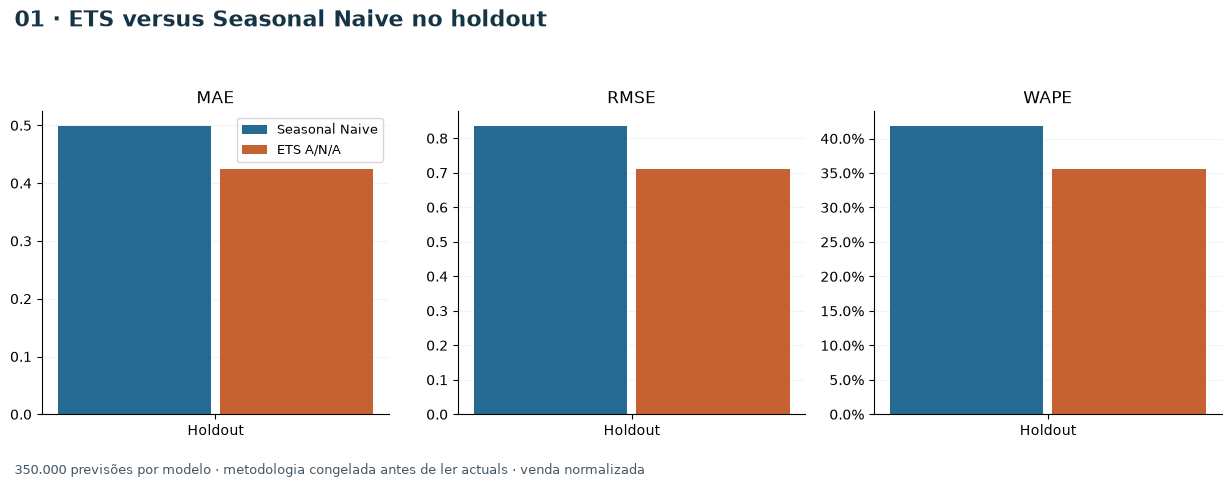

,level,abc_class,xyz_class,stockout_exposure,censoring_risk_flag,persistent_underforecast_flag,demand_observation_risk_cell,mae_sn,rmse_sn,wape_sn,...,wape_ets,bias_ets,bias_pct_ets,underforecast_rate_ets,actual_total_ets,n_forecasts_ets,n_series_ets,improvement_mae,improvement_rmse,improvement_wape
15,global,NaN,NaN,NaN,None,None,NaN,0.499071,0.835819,0.418314,...,0.356215,-0.026863,-0.022516,0.5166,417568.523,350000,50000,0.148451,0.148965,0.148451


In [2]:
fig=PLOTS[0](data)
save_figure(fig,1,root)
plt.show()
display(data['paired_comparison'].loc[lambda x:x.level.eq('global')])

## 2. WAPE e consistência temporal

Quatro folds são referência descritiva, não intervalo de confiança.

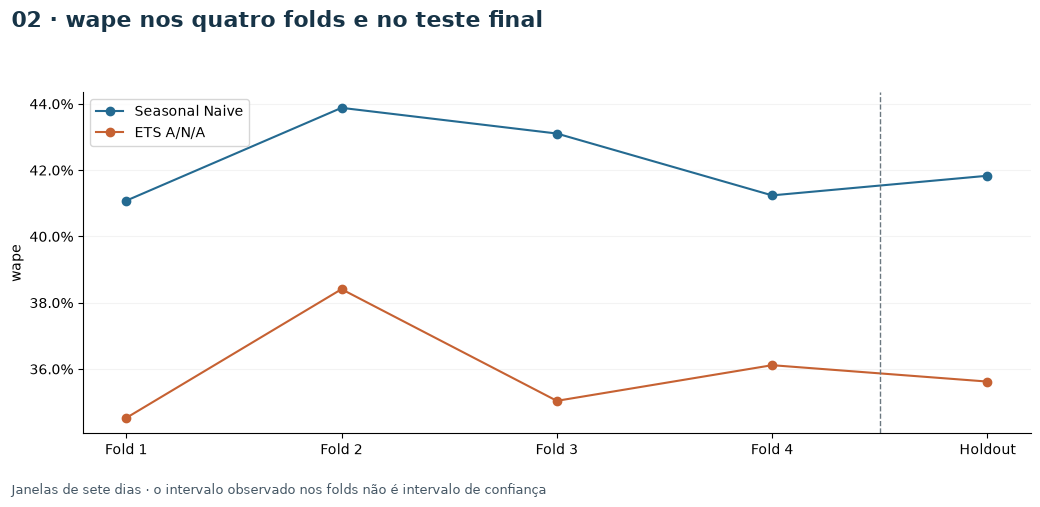

In [3]:
fig=PLOTS[1](data)
save_figure(fig,2,root)
plt.show()


## 3. Bias temporal

Não existe limite prévio de aceitabilidade operacional; não inventar um após abrir eval.

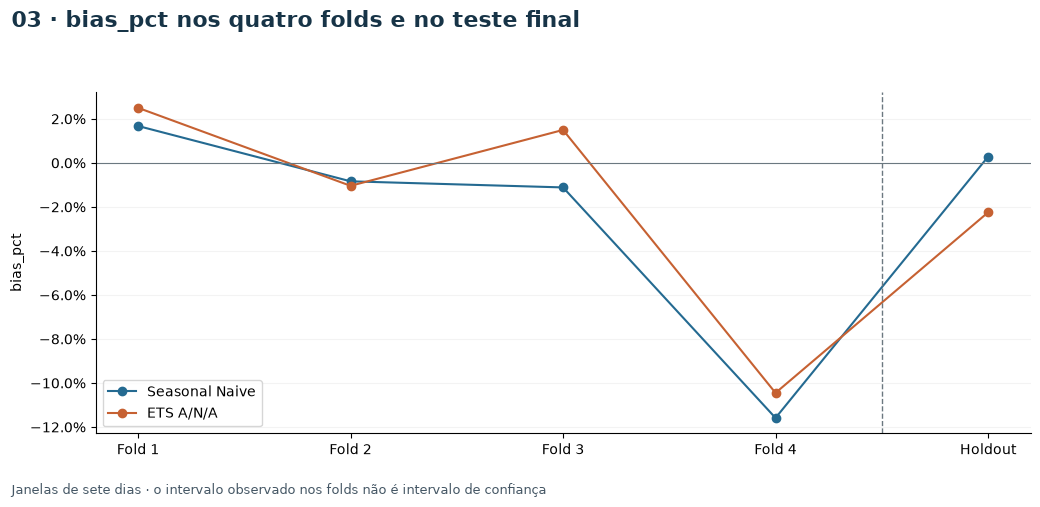

In [4]:
fig=PLOTS[2](data)
save_figure(fig,3,root)
plt.show()


## 4. ABC

Classes congeladas em 25/06; venda observada normalizada não é receita.

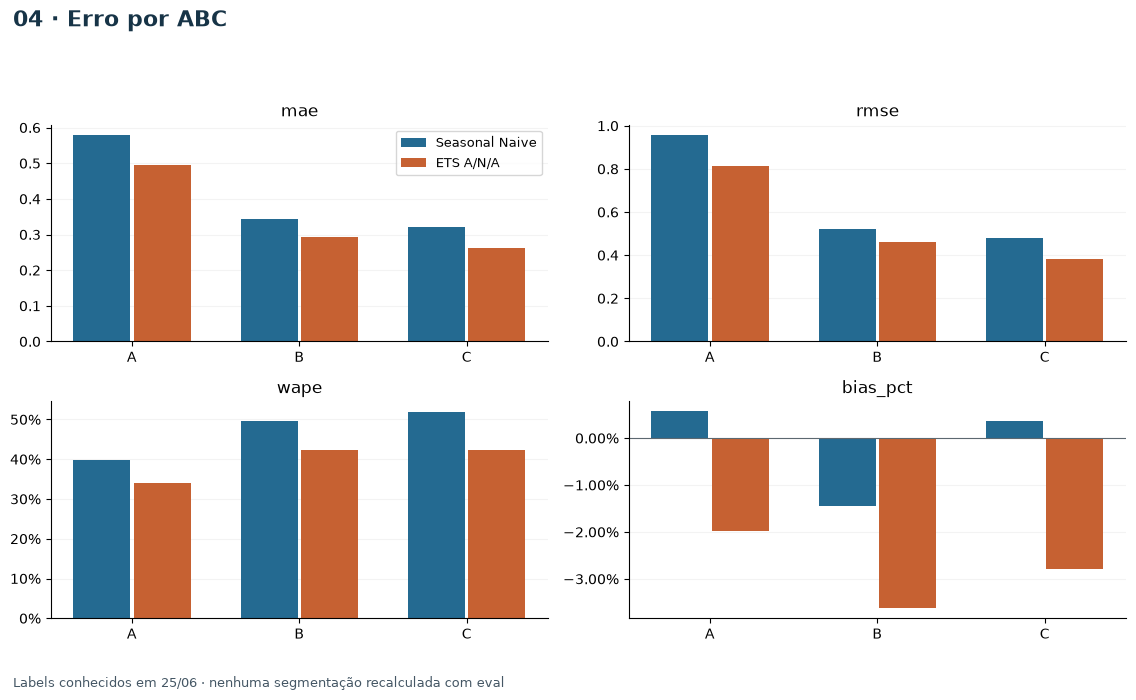

In [5]:
fig=PLOTS[3](data)
save_figure(fig,4,root)
plt.show()


## 5. XYZ

Classes conhecidas antes da origem; nenhuma recalibração no holdout.

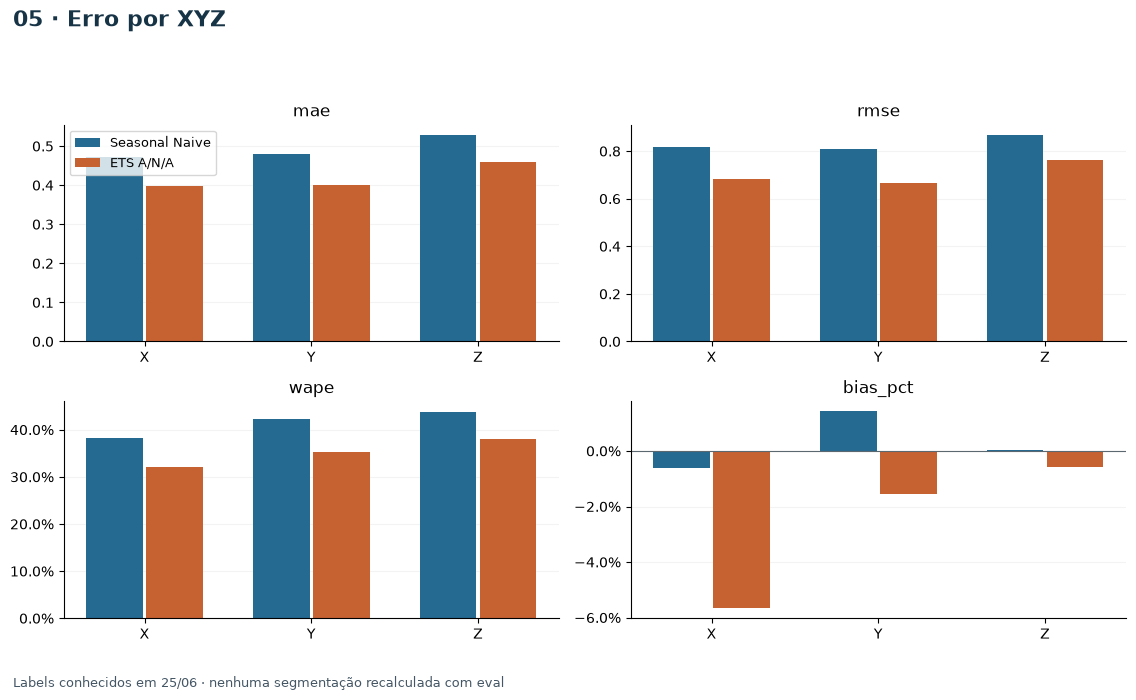

In [6]:
fig=PLOTS[4](data)
save_figure(fig,5,root)
plt.show()


## 6. Persistência prospectiva

Bias histórico negativo e pelo menos três folds negativos: 16.529 séries fixas.

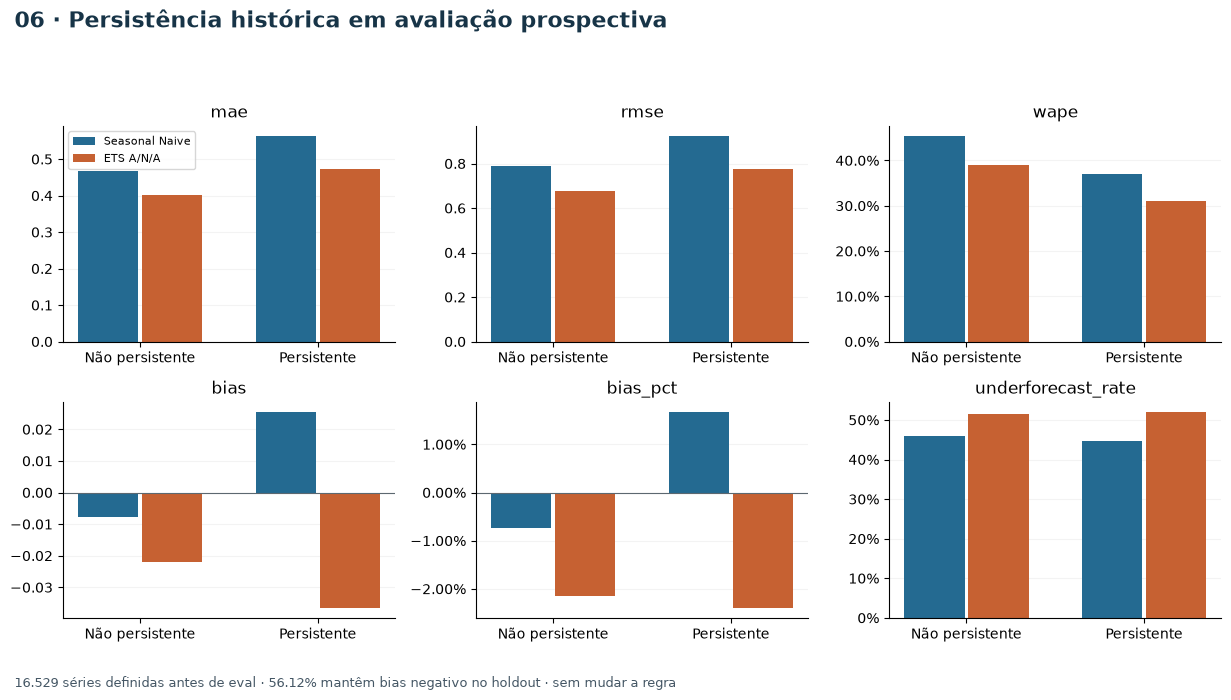

,persistent_underforecast_flag,n_series,negative_holdout_bias_series,negative_holdout_bias_rate,zero_actual_series
0,False,33471,18172,0.542918,60
1,True,16529,9276,0.561195,1


In [7]:
fig=PLOTS[5](data)
save_figure(fig,6,root)
plt.show()
display(data['persistence_retention'])

## 7. Matriz de risco

Sinais pré-holdout, sem score; não inferir causalidade ou demanda perdida.

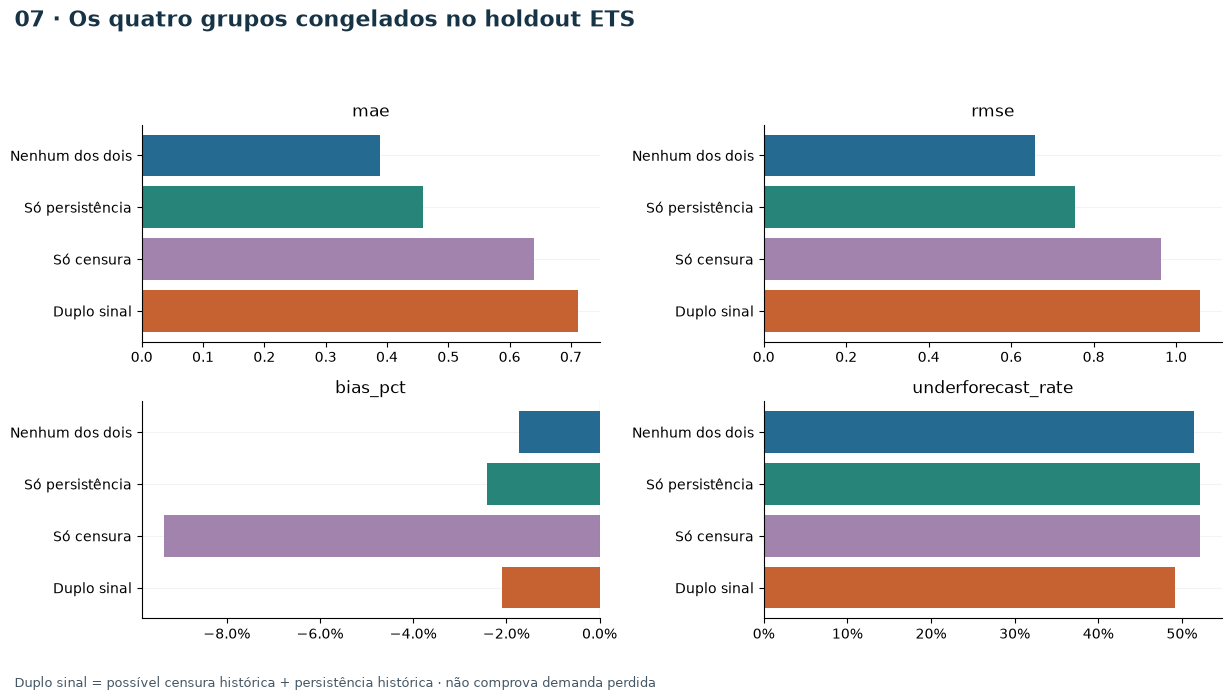

In [8]:
fig=PLOTS[6](data)
save_figure(fig,7,root)
plt.show()


## 8. A e duplo sinal

As mesmas 706 séries identificadas antes da abertura; sem seleção pelo resultado.

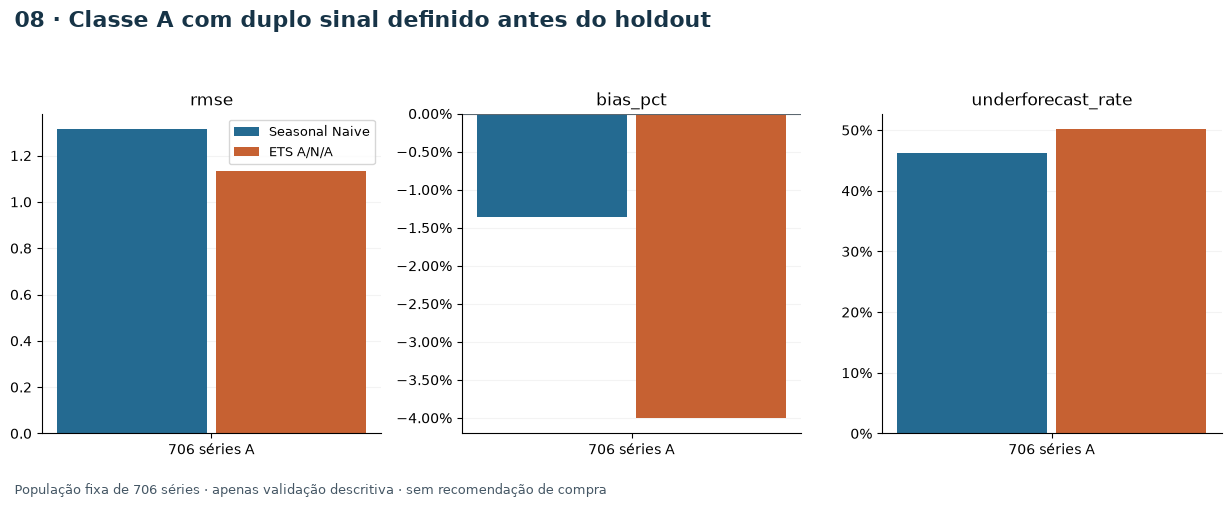

In [9]:
fig=PLOTS[7](data)
save_figure(fig,8,root)
plt.show()


## 9. Incerteza histórica

Quartis congelados; associação com erro futuro pode refletir escala e dependência entre séries.

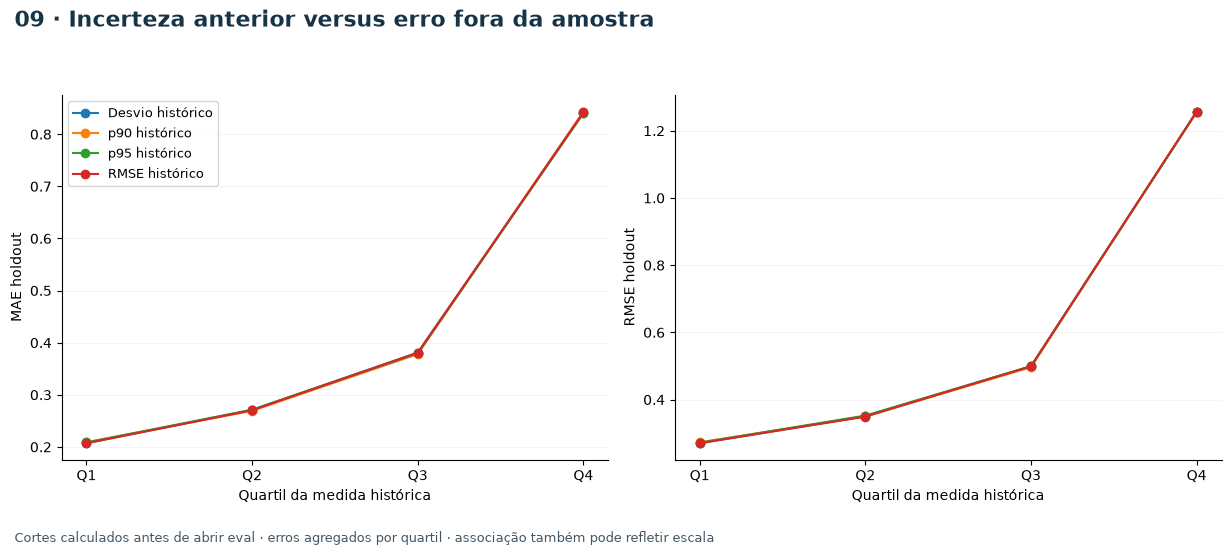

,historical_metric,holdout_metric,n_series,spearman
0,error_std,mae,50000,0.726828
1,error_std,rmse,50000,0.735952
2,rmse,mae,50000,0.730036
3,rmse,rmse,50000,0.739605
4,p90_absolute_error,mae,50000,0.728400
5,p90_absolute_error,rmse,50000,0.737248
6,p95_absolute_error,mae,50000,0.725376
7,p95_absolute_error,rmse,50000,0.734899


In [10]:
fig=PLOTS[8](data)
save_figure(fig,9,root)
plt.show()
display(data['uncertainty_association'])

## 10. Exemplos anteriores

Sete regras da Fase 6, sem cherry-picking no holdout; painéis têm escalas diferentes.

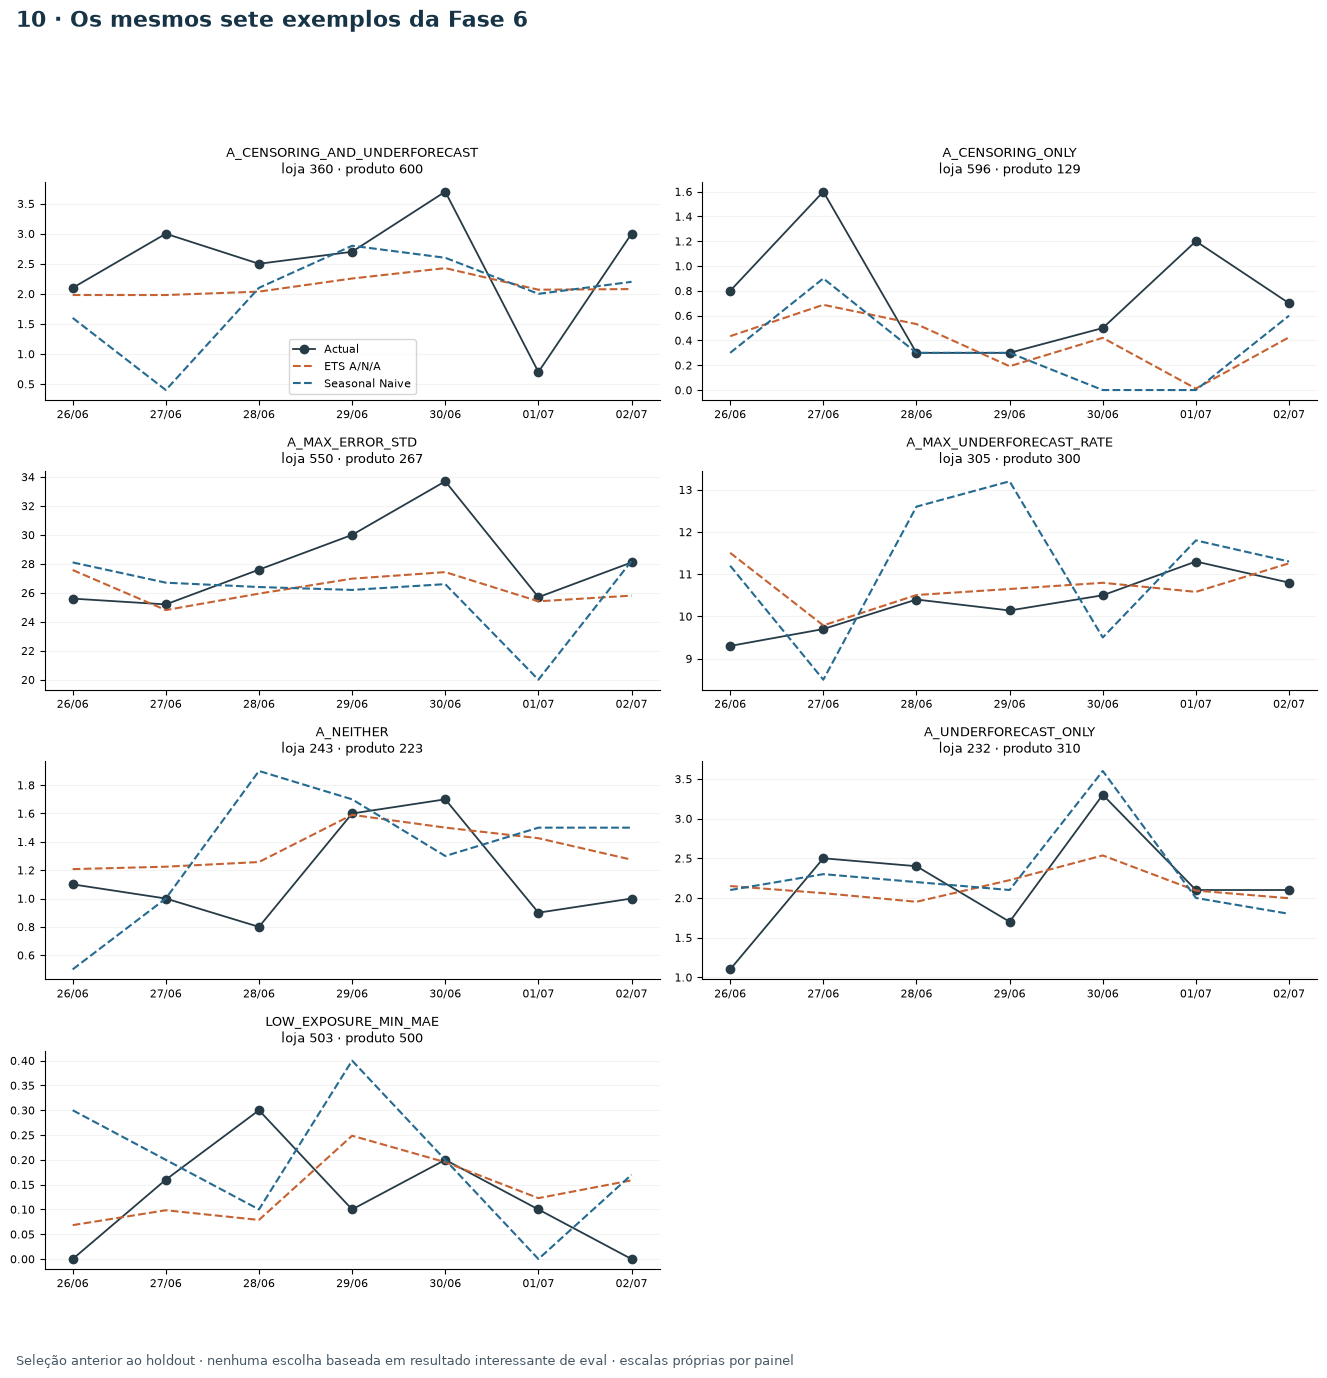

,model,historical_low_scale,n_forecasts,n_series,n_products,n_folds,actual_total,forecast_total,mae,rmse,...,error_q50,error_q75,error_q90,underforecast_days,underforecast_rate,overforecast_days,overforecast_rate,exact_forecast_days,total_underforecast_amount,mean_underforecast_amount_when_positive
0,ets_ana,False,332493,47499,830,1,410744.673,402539.416886,0.435902,0.726013,...,-0.015022,0.253850,0.576923,171164,0.514790,160932,0.484016,397,76569.814755,0.447348
1,ets_ana,True,17507,2501,316,1,6823.850,5627.046109,0.217611,0.323436,...,-0.030814,0.115037,0.251406,9646,0.550980,7668,0.437996,193,2503.257723,0.259513
2,seasonal_naive,False,332493,47499,830,1,410744.673,413177.455000,0.512205,0.853311,...,0.000000,0.300000,0.700000,150570,0.452852,152758,0.459432,29165,83935.825000,0.557454
3,seasonal_naive,True,17507,2501,316,1,6823.850,5548.800000,0.249634,0.370742,...,0.000000,0.100000,0.300000,8515,0.486377,6003,0.342891,2989,2822.700000,0.331497


,model,eval_stockout,n_forecasts,n_series,n_products,n_folds,actual_total,forecast_total,mae,rmse,...,error_q50,error_q75,error_q90,underforecast_days,underforecast_rate,overforecast_days,overforecast_rate,exact_forecast_days,total_underforecast_amount,mean_underforecast_amount_when_positive
0,ets_ana,False,206562,50000,865,1,255541.230,244684.582879,0.401634,0.673414,...,0.006157,0.241678,0.493530,101660,0.492152,104593,0.506352,309,46909.481852,0.461435
1,ets_ana,True,143438,44126,815,1,162027.293,163481.880116,0.458608,0.762583,...,-0.050124,0.248368,0.687363,79150,0.551806,64007,0.446235,281,32163.590626,0.406362
2,seasonal_naive,False,206562,50000,865,1,255541.230,253579.528000,0.481350,0.797899,...,0.000000,0.300000,0.700000,87978,0.425916,100087,0.484537,18497,50695.123000,0.576225
3,seasonal_naive,True,143438,44126,815,1,162027.293,165146.727000,0.524591,0.887584,...,0.000000,0.300000,0.800000,71107,0.495733,58674,0.409055,13657,36063.402000,0.507171


In [11]:
fig=PLOTS[9](data)
save_figure(fig,10,root)
plt.show()
display(data['low_scale'])
display(data['contemporary_stockout'])

## Conclusão congelada após avaliação

**B — confirmação parcial da metodologia conjunta**

A vantagem de erro do ETS recebeu forte confirmação fora da amostra: MAE/WAPE melhoram 14,85% e RMSE 14,90% frente ao Seasonal Naive, com ganho nas três métricas em todos os segmentos predefinidos. WAPE ETS de 35,62% está dentro da faixa dos folds (34,52%–38,41%), abaixo da média de 36,02% e do fold 4 (36,12%). MAE/RMSE são maiores que no agregado do backtest, mas permanecem dentro da faixa dos folds; nenhuma falha ou fallback ocorreu. Porém, o bias_pct ETS de −2,25% fica mais distante de zero que o +0,28% do Seasonal Naive. Não existe threshold anterior que permita declarar esse bias operacionalmente aceitável. A classificação conjunta B expressa confirmação parcial das regras de risco e a ressalva de bias; não significa ganho de erro pequeno ou inferioridade preditiva do ETS. Não se escolheu um limite numérico retrospectivo nem se alterou a metodologia.

As 16.529 persistentes apresentam bias mais negativo e frequência de subprevisão apenas ligeiramente maior: −0,03655/−2,40%/51,94%, contra −0,02208/−2,14%/51,52% nas demais. Mantêm bias negativo 9.276 séries (56,12%), contra 54,29% das não persistentes: separação prospectiva fraca. Duplo sinal tem MAE/RMSE maiores que NEITHER (0,7110/1,0573 contra 0,3887/0,6591) e bias mais negativo, mas menor underforecast_rate (49,12% contra 51,49%); CENSORING_ONLY tem bias_pct ainda mais negativo (−9,36%). Portanto, não se confirmou uma ordenação uniforme de subprevisão pela matriz. A flag de possível censura continua associada a maior magnitude de erro, sem maior frequência global de dias subprevistos. Já a incerteza histórica se associa ao erro futuro: Spearman aproximadamente 0,725–0,740 e crescimento monotônico de MAE/RMSE nos quatro quartis congelados. Isso é associação descritiva, também influenciada por escala; não comprova demanda perdida, causalidade ou suficiência de estoque. As flags, os quartis e os exemplos permanecem inalterados.

Uma semana não prova estabilidade futura. Eval não será reutilizado para retuning. Sem reposição ou Power BI.